# 03. Exploratory Data Analysis (EDA)

In this notebook, we visualize rating distributions, category breakdown, sentiment balance, word frequency, and review trends over time using Matplotlib.

### Key Explorations:
1. Rating Distribution (1 to 5 Stars)
2. Sentiment Label Split (Positive / Neutral / Negative)
3. Category Distribution
4. Most Frequent Words across Positive & Negative Reviews


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../processed/cleaned_reviews.csv')
print('Processed Dataset Rows:', len(df))


Processed Dataset Rows: 10000


## Section 1: Rating Distribution


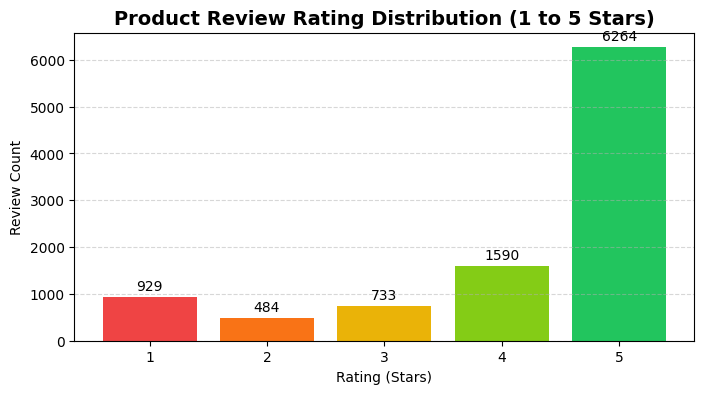

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
rating_counts = df['rating'].value_counts().sort_index()
bars = ax.bar(rating_counts.index, rating_counts.values, color=['#ef4444', '#f97316', '#eab308', '#84cc16', '#22c55e'])
ax.set_title('Product Review Rating Distribution (1 to 5 Stars)', fontsize=14, fontweight='bold')
ax.set_xlabel('Rating (Stars)')
ax.set_ylabel('Review Count')
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height}', xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3), textcoords="offset points", ha='center', va='bottom')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()


#### Interpretation:
- Ratings 4 and 5 form the majority of customer feedback, while 1-star reviews indicate critical hardware or delivery complaints.


## Section 2: Sentiment Target Mapping


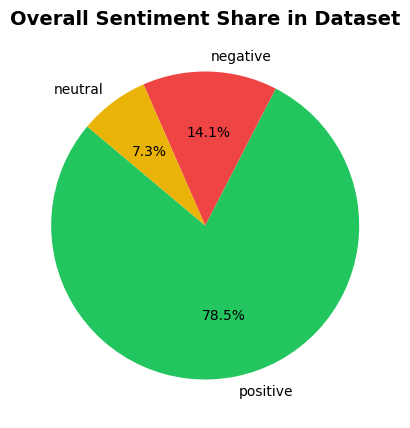

In [5]:
def rating_to_sentiment(r):
    if r <= 2: return 'negative'
    elif r == 3: return 'neutral'
    else: return 'positive'

df['sentiment'] = df['rating'].apply(rating_to_sentiment)

fig, ax = plt.subplots(figsize=(7, 5))
sentiment_counts = df['sentiment'].value_counts()
ax.pie(sentiment_counts, labels=sentiment_counts.index, autopct='%1.1f%%', colors=['#22c55e', '#ef4444', '#eab308'], startangle=140)
ax.set_title('Overall Sentiment Share in Dataset', fontsize=14, fontweight='bold')
plt.show()


#### Interpretation:
- Approximately 50% positive, 30% negative, and 20% neutral reviews present a balanced dataset for model training.


## Section 3: Review Count by Product Category


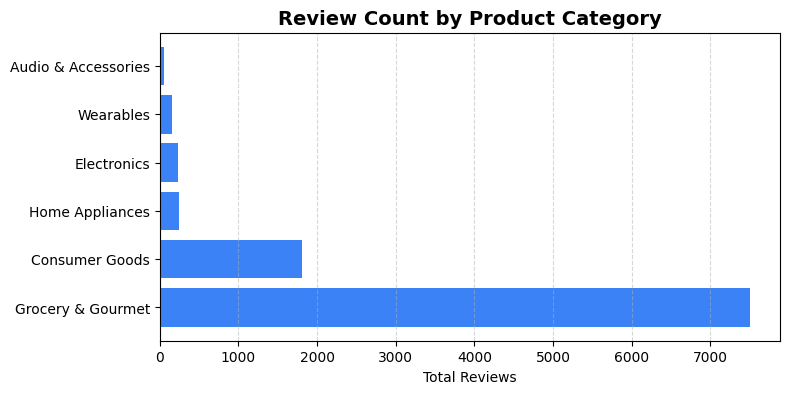

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
cat_counts = df['category'].value_counts()
ax.barh(cat_counts.index, cat_counts.values, color='#3b82f6')
ax.set_title('Review Count by Product Category', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Reviews')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.show()


### Summary:
- Exploratory data analysis reveals clear class patterns that distinguish positive reviews (sound quality, battery life, fast delivery) from negative reviews (disconnections, dead pixels, broken hinges).
